# 00 · Welcome to NHyDB

**NHyDB 0.27.1 notebook series · v1**

Your starting point – five to ten minutes. What NHyDB is (and is not), how its ideas map to terms you know from other databases, a first taste in ten lines, quick answers to the most common questions, and a map of the whole notebook series.

> **Who is this for?** This notebook starts with a short introduction and continues with runnable examples. **New to NHyDB?** Read from top to bottom – every idea is introduced before it is used. **Already know the basics?** Skip the sections marked 📘 *Background* and jump to the experiments marked ▶. All cells run from top to bottom; optional deep dives are marked ⏩ *Advanced*.

**What you will learn**

* NHyDB in three sentences – and the three layers every notebook uses
* a dictionary from classic database terms to NHyDB terms
* a ten-line program: write a value and find it again by its number `N`
* short, checkable answers to the most common questions
* which notebook to read next – three reading paths

**Recommended before:** Nothing – this notebook can be read on its own.

### Setup

The next cell checks the environment and defines a few small plotting helpers used in
this notebook. It is collapsed because it is not about NHyDB itself – feel free to open
it. Every database in this notebook lives in a temporary folder that is removed at
the end.

In [1]:
import math
import os
import shutil
import sys
import tempfile

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

import nhydb

# --- environment check ---------------------------------------------------------
EXPECTED = "0.27.1"
print(f"Python {sys.version.split()[0]} · nhydb {nhydb.ENGINE_VERSION} · "
      f"file format {nhydb.FILE_FORMAT_VERSION} · matplotlib {matplotlib.__version__}")
if nhydb.ENGINE_VERSION != EXPECTED:
    print(f"⚠ This notebook was written for NHyDB {EXPECTED}; results may differ.")

# --- a private temporary folder for all databases of this notebook --------------
WORKDIR = tempfile.mkdtemp(prefix="nhydb_notebook_")


def db_path(name):
    """Path of a new database file inside the temporary folder."""
    return os.path.join(WORKDIR, name)


def cleanup():
    shutil.rmtree(WORKDIR, ignore_errors=True)


def file_sizes(path):
    """Sizes of the files that belong to a database (bytes)."""
    folder, base = os.path.split(path)
    return {f: os.path.getsize(os.path.join(folder, f))
            for f in sorted(os.listdir(folder)) if f.startswith(base)}


# --- one visual language for the whole series -----------------------------------
# Layer A (mathematical address space) = blue tones, layer B (logical data model) =
# green, layer C (storage engine) = slate grey. Lanes and boundary points belong to A.
COLORS = {
    "A": "#1d4ed8", "A_light": "#dbeafe",
    "B": "#15803d", "B_light": "#dcfce7",
    "C": "#475569", "C_light": "#e2e8f0",
    "NL": "#2563eb", "NR": "#7c3aed",
    "GZ": "#dc2626", "N0": "#9ca3af",
    "attention": "#ea580c", "ok": "#16a34a", "bad": "#dc2626",
}
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})


def kind_of(n):
    """'NL', 'NR', 'GZ' or 'N0' for a natural number n >= 1 (computed by NHyDB)."""
    try:
        return nhydb.n_to_dynadron_address(n)["lane_name"]
    except nhydb.AddressError:
        return "GZ" if math.isqrt(n) ** 2 == n else "N0"


def group_of(n):
    """The group G whose interval [G(G-1), G(G+1)) contains n."""
    g = math.isqrt(n)
    return g + 1 if n - g * g >= g else g       # N0(g+1) and the NL cells of g+1 lie above g² + g − 1


KIND_LABEL = {"NL": "NL cell", "NR": "NR cell", "GZ": "GZ point (G²)", "N0": "N0 point (G·(G−1))"}


def plot_path(ax, steps, title=None):
    """'From input to value': boxes coloured by layer A/B/C, connected by arrows.

    ``steps`` is a list of (layer, heading, text) with layer in {"A", "B", "C"}.
    """
    n = len(steps)
    width, gap = 1.0, 0.35
    for i, (layer, head, text) in enumerate(steps):
        x = i * (width + gap)
        ax.add_patch(FancyBboxPatch((x, 0), width, 1, boxstyle="round,pad=0.02,rounding_size=0.06",
                                    facecolor=COLORS[layer + "_light"], edgecolor=COLORS[layer], lw=1.6))
        ax.text(x + width / 2, 0.80, head, ha="center", va="center", fontsize=8.5,
                fontweight="bold", color=COLORS[layer])
        ax.text(x + width / 2, 0.40, text, ha="center", va="center", fontsize=8, color="#111827",
                wrap=True)
        if i < n - 1:
            ax.annotate("", xy=(x + width + gap - 0.02, 0.5), xytext=(x + width + 0.02, 0.5),
                        arrowprops=dict(arrowstyle="-|>", color="#334155", lw=1.3))
    ax.set_xlim(-0.1, n * (width + gap) - gap + 0.1)
    ax.set_ylim(-0.35, 1.15)
    ax.axis("off")
    for j, (layer, name) in enumerate([("A", "A · address space"), ("B", "B · data model"),
                                       ("C", "C · storage engine")]):
        ax.text(j * 1.6, -0.25, "■ " + name, color=COLORS[layer], fontsize=8.5, fontweight="bold")
    if title:
        ax.set_title(title)

import importlib
import pandas as pd

Python 3.14.5 · nhydb 0.27.1 · file format 0.16 · matplotlib 3.11.2


## 📘 NHyDB in three sentences

1. **Every value has a mathematical address.** It lives in a cell `(R, u, v, lane)` – realm, two
   coordinates and one of two lanes – and every cell *is* exactly one natural number `N`,
   computed from the address, never stored and never assigned twice.
2. **The structure comes from mathematics, not from tables.** The cells are arranged in the
   *Dynadron*, a geometric order of all natural numbers; layouts and formulas decide how your
   records and objects are placed on these cells.
3. **It is a complete storage engine.** A native Rust core with Python bindings: typed fields,
   indexes, queries and read-only SQL, NumPy batches, an append-only file with commits and crash
   recovery, and a schema (layout plan) stored encrypted outside the data file.

**What NHyDB is not:** there are no tables with rows and key columns, nothing hands out IDs, and
NHySQL only *reads* (`SELECT`) – writing happens through the Python API.

## 1 · A dictionary for the classic database mind

| Classic database | NHyDB | Note |
|---|---|---|
| database / schema | database with realms | a realm is a numbered address range |
| table | **layout** (CLASSIC, COLUMN, PACKED, CUSTOM, MATH) | decides which cells a record uses |
| row | **record** – in CLASSIC the cells of one `u` | |
| column | **field** – in CLASSIC one `v` | typed: 15 field types |
| primary key | **none needed** | the cell number `N` *is* the address |
| auto-increment | **none needed** | coordinates come from your data or a formula |
| NULL | null value or simply no cell | missing cells cost nothing |
| DELETE | a tombstone – a new state | the file is append-only |
| index | VALUE / TOKEN / TRIGRAM / FULLTEXT index | for search by **content** |
| SQL | QueryEngine and NHySQL (`SELECT`) | |
| schema file | encrypted **layout plan** + key file | stored next to the data file |

## 2 · Check your environment

The series needs `nhydb` 0.27.1 and uses NumPy, pandas and Matplotlib for tables and figures.

In [2]:
rows = [{"package": "Python", "version": sys.version.split()[0], "needed for": "everything"}]
for name, purpose in (("nhydb", "everything"), ("numpy", "notebooks 10, 13 and batch examples"),
                      ("pandas", "tables in all notebooks"), ("matplotlib", "figures in all notebooks")):
    try:
        mod = importlib.import_module(name)
        version = getattr(mod, "ENGINE_VERSION", getattr(mod, "__version__", "?"))
    except ImportError:
        version = "MISSING – pip install " + name
    rows.append({"package": name, "version": version, "needed for": purpose})
env = pd.DataFrame(rows).set_index("package")
assert env.loc["nhydb", "version"] == "0.27.1", "please install nhydb 0.27.1: pip install nhydb==0.27.1"
env

,version,needed for
package,,
Python,3.14.5,everything
nhydb,0.27.1,everything
numpy,2.5.4,"notebooks 10, 13 and batch examples"
pandas,3.0.6,tables in all notebooks
matplotlib,3.11.2,figures in all notebooks


## 3 · A first taste in ten lines

▶ **Run it:** create a database, store one planet, compute the number of one of its cells – and
read the value back **only by that number**.

In [3]:
path = db_path("first.nhydb")
with nhydb.create(path) as db:
    db.create_realm(1, "planets")
    db.create_shape(1, 1, "planet", [{"v": 1, "name": "name", "type": "utf8"},
                                     {"v": 2, "name": "mass", "type": "f64"},
                                     {"v": 3, "name": "moons", "type": "u16"}])
    db.create_classic_layout(1, 1, "planets", shape_id=1)
    db.put_dense_batch(1, 1, [["Mercury", 0.330, 0], ["Venus", 4.87, 0], ["Earth", 5.97, 1]])

N = nhydb.dynadron_n(1, 3, 3, "NL")                 # planet 3, field 3 (moons), lane NL
with nhydb.open(path) as db:
    print(f"N = {N} →", db.get_n(N, mode="cell")["value"], "moon(s) of", db.get_record(1, 3)["name"])

N = 33 → 1 moon(s) of Earth


**What happened?** We never created a key or an ID. The moons of Earth sit in the cell
`(R = 1, u = 3, v = 3, NL)`; its group is `G = u + v = 6`, so `N = 6² − 3 = 33`. Any program that
knows the number 33 can read the value.

## 4 · The three layers of every notebook

Every value can be seen on three levels. The notebooks always use the same colours:
**green** for your data model, **blue** for the mathematical address space, **grey** for the
storage engine.

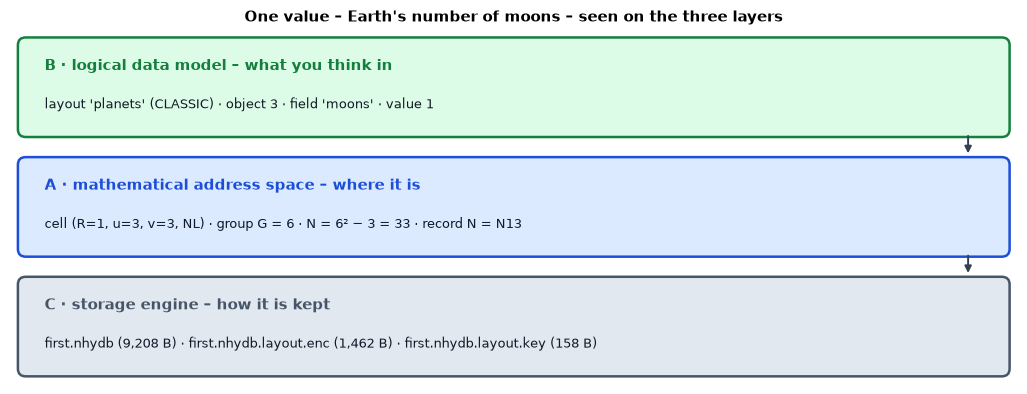

In [4]:
with nhydb.open(path) as db:
    cell = db.get_n(N, mode="cell")
    sizes = file_sizes(path)

fig, ax = plt.subplots(figsize=(13, 4.6))
bands = [
    ("B", "B · logical data model – what you think in",
     f"layout '{cell['layout_name']}' ({cell['layout_kind']}) · object {cell['object']} · field '{cell['field']}' · value {cell['value']}"),
    ("A", "A · mathematical address space – where it is",
     f"cell (R={cell['realm']}, u={cell['u']}, v={cell['v']}, {cell['lane_name']}) · group G = {cell['u'] + cell['v']} · "
     f"N = {cell['u'] + cell['v']}² − {cell['u']} = {N} · record N = {cell['record_N']}"),
    ("C", "C · storage engine – how it is kept",
     " · ".join(f"{name} ({size:,} B)" for name, size in sizes.items() if size)),
]
for i, (layer, title, text) in enumerate(bands):
    y = 2 - i
    ax.add_patch(FancyBboxPatch((0, y * 1.25), 10, 1.0, boxstyle="round,pad=0.02,rounding_size=0.08",
                                facecolor=COLORS[layer + "_light"], edgecolor=COLORS[layer], lw=1.8))
    ax.text(0.25, y * 1.25 + 0.68, title, fontsize=10.5, fontweight="bold", color=COLORS[layer])
    ax.text(0.25, y * 1.25 + 0.28, text, fontsize=9.5, color="#111827")
    if i < 2:
        ax.annotate("", xy=(9.6, y * 1.25 - 0.22), xytext=(9.6, y * 1.25 + 0.02),
                    arrowprops=dict(arrowstyle="-|>", color="#334155", lw=1.4))
ax.set_xlim(-0.1, 10.1)
ax.set_ylim(-0.1, 3.6)
ax.axis("off")
ax.set_title("One value – Earth's number of moons – seen on the three layers", fontweight="bold")
plt.show()

## 5 · Myths and questions

Short answers – each one checked by the engine right here.

**"Where is the primary key?"** There is none – the address is the key. `N` is computed from
`(R, u, v, lane)` and turned back into the address with integer arithmetic.

In [5]:
a = nhydb.n_to_dynadron_address(33)
print("N33 →", (a["realm"], a["u"], a["v_local"], a["lane_name"]), "→", nhydb.dynadron_n(1, a["u"], a["v_local"], a["lane"]))
assert nhydb.dynadron_n(1, a["u"], a["v_local"], a["lane"]) == 33

N33 → (1, 3, 3, 'NL') → 33


**"Could two cells get the same number?"** No. All natural numbers are arranged in rows (groups),
each number has exactly one place – notebook 01 shows why. A quick check over 20,000 cells:

In [6]:
numbers = [nhydb.dynadron_n(1, u, v, lane) for lane in ("NL", "NR") for u in range(1, 101) for v in range(1, 101)]
print(len(numbers), "cells →", len(set(numbers)), "different numbers")
assert len(numbers) == len(set(numbers))

20000 cells → 20000 different numbers


**"What about really big numbers?"** They stay exact. Python integers and the Rust core compute with
arbitrarily large natural numbers – a cell in realm 23 has a number with more than 200 digits:

In [7]:
big = nhydb.dynadron_n(23, 14, 744, "NL")
back = nhydb.n_to_dynadron_address(big)
print(f"N has {len(str(big))} digits and maps back to realm {back['realm']}, u = {back['u']}, v = {back['v_local']}")
assert (back["realm"], back["u"], back["v_local"]) == (23, 14, 744)

N has 203 digits and maps back to realm 23, u = 14, v = 744


**"Doesn't a gigantic address space need a gigantic file?"** No – only stored values take space:

In [8]:
far = db_path("far.nhydb")
with nhydb.create(far) as db:
    db.create_realm(1, "far")
    db.commit()
    empty = os.path.getsize(far)
    db.put_cell(1, 10**30, 10**60, "hello from far away", type="utf8", commit=True)
print(f"value at u = 10^30, v = 10^60: the file grew by {os.path.getsize(far) - empty} bytes")
assert os.path.getsize(far) - empty < 300

value at u = 10^30, v = 10^60: the file grew by 128 bytes


**"Is my data encrypted?"** Only the **schema** – the layout plan with realms, shapes, layouts and
indexes – is encrypted (AES-256-GCM) in a separate file and bound to a key file. The **data file is
not encrypted**: protect it with file permissions or disk encryption. Checked directly on the bytes:

In [9]:
data_bytes = open(path, "rb").read()
plan_bytes = open(path + ".layout.enc", "rb").read()
print("value 'Earth' readable in the data file:      ", b"Earth" in data_bytes)
print("layout name 'planets' readable in data file:  ", b"planets" in data_bytes)
print("layout name 'planets' readable in plan file:  ", b"planets" in plan_bytes)
assert b"Earth" in data_bytes and b"planets" not in plan_bytes

value 'Earth' readable in the data file:       True
layout name 'planets' readable in data file:   False
layout name 'planets' readable in plan file:   False


**"Is NHySQL a full SQL database?"** No – it reads (`SELECT`), it does not write:

In [10]:
with nhydb.open(path) as db:
    print(db.sql("SELECT name FROM planets WHERE moons > 0")["rows"])
    try:
        db.sql("INSERT INTO planets VALUES ('Mars', 0.642, 2)")
    except nhydb.SQLSyntaxError as e:
        print("INSERT →", type(e).__name__ + ":", e)

[{'name': 'Earth'}]
INSERT → SQLSyntaxError: SELECT expected (line 1, column 1, near "INSERT INTO planets VALUES ('Mar")


## 6 · The notebook series

| No. | Notebook | Key question |
|---:|---|---|
| 00 | [Welcome to NHyDB](00_start_here_v1.ipynb) | What is it, where do I start? |
| 01 | [The Address Is the Identity](01_the_address_is_the_identity_v1.ipynb) | Why is every cell exactly one number? |
| 02 | [From Mathematics to Stored Values](02_from_address_to_data_v1.ipynb) | How do I store something there? |
| 03 | [Records, Fields and Lanes](03_records_fields_and_lanes_v1.ipynb) | What does the data model look like? |
| 04 | [One Dataset, Different Layouts](04_layouts_side_by_side_v1.ipynb) | How are records placed on cells? |
| 05 | [MATH_MAP: A Text, a Formula, a Database](05_math_map_text_and_formula_lab_v1.ipynb) | How do I choose the place by a formula? |
| 06 | [Scientific Results in Cells (MATH_LONG)](06_scientific_results_in_cells_v1.ipynb) | How do I keep results of computations? |
| 07 | [Huge Addresses, Exact Integers](07_realms_and_huge_numbers_v1.ipynb) | How big is the address space really? |
| 08 | [Addresses Are Not Search Indexes](08_addresses_are_not_indexes_v1.ipynb) | How do I find data by content? |
| 09 | [Asking Questions of the Data](09_queries_and_sql_v1.ipynb) | How do I query? |
| 10 | [From Single Cells to NumPy Batches](10_numpy_batches_v1.ipynb) | How do I handle mass data? |
| 11 | [What Actually Lives on Disk?](11_what_lives_on_disk_v1.ipynb) | Why is the data safely stored? |
| 12 | [One Layout Plan, Two Views](12_encrypted_layout_and_key_v1.ipynb) | What does the layout plan protect, and how? |
| 13 | [Measure, Don't Assume](13_benchmark_lab_v1.ipynb) | How fast is it on my machine? |
| 14 | [Build a Small Real Application](14_complete_application_v1.ipynb) | What does a whole application look like? |

**Reference notebooks** (generated from the
[Python Cookbook](https://github.com/nhydb/NHyDB/blob/main/docs/cookbook/PYTHON_COOKBOOK.md) – every
API example, ready to run):
[R01 Basics](../reference/R01_basics_v1.ipynb) ·
[R02 Addresses, types, ranges](../reference/R02_addresses_types_ranges_v1.ipynb) ·
[R03 Indexes, queries, SQL](../reference/R03_indexes_queries_sql_v1.ipynb) ·
[R04 NumPy and layouts](../reference/R04_numpy_and_layouts_v1.ipynb) ·
[R05 MATH_MAP](../reference/R05_math_map_v1.ipynb) ·
[R06 Operations](../reference/R06_operations_v1.ipynb) ·
[R07 Limitations and API reference](../reference/R07_limitations_and_api_reference_v1.ipynb)

### Three reading paths

| Path | Notebooks | For whom |
|---|---|---|
| **Core path** (about one hour) | 00 → 01 → 02 → 05 → 12 | everyone: the idea, the database, the formula, the protection |
| **Mathematics path** | 01 → 05 → 06 → 07 | mathematicians and the curious: Dynadron, formulas, huge numbers |
| **Developer path** | 02 → 03 → 04 → 08 → 09 → 10 → 11 → 13 → 14 | building applications |

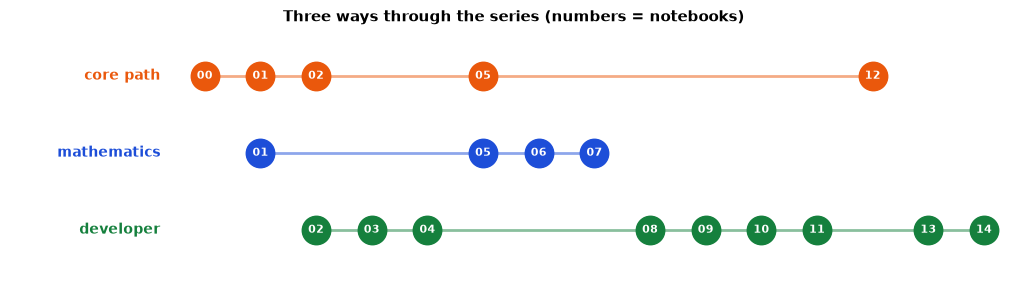

In [11]:
fig, ax = plt.subplots(figsize=(13, 3.2))
paths_ = [("core path", ["00", "01", "02", "05", "12"], COLORS["attention"]),
          ("mathematics", ["01", "05", "06", "07"], COLORS["A"]),
          ("developer", ["02", "03", "04", "08", "09", "10", "11", "13", "14"], COLORS["B"])]
for row, (name, nbs, color) in enumerate(paths_):
    y = 2 - row
    xs = [int(n) for n in nbs]
    ax.plot(xs, [y] * len(xs), "-", color=color, lw=2, alpha=0.5)
    ax.scatter(xs, [y] * len(xs), s=420, color=color, zorder=3)
    for x, n in zip(xs, nbs):
        ax.text(x, y, n, ha="center", va="center", color="white", fontsize=8, fontweight="bold", zorder=4)
    ax.text(-0.8, y, name, ha="right", va="center", fontsize=10, color=color, fontweight="bold")
ax.set_xlim(-3.5, 14.6)
ax.set_ylim(-0.6, 2.6)
ax.axis("off")
ax.set_title("Three ways through the series (numbers = notebooks)")
plt.show()

## 7 · License

NHyDB is **source-available, not open source**. It is published under the *NHyDB / dNHyDB
Experimental Software License 1.0* (`LICENSE.md` in the
[repository](https://github.com/nhydb/NHyDB/blob/main/LICENSE.md)): free use is limited to
**non-production purposes** – unlimited for private individuals, time-limited for teaching,
research and businesses – and **production use requires a separate written license**. Please read
the license text before using the software. Project website: <https://nhydb.de/nhydb/>.

## Summary

* NHyDB stores every value in a cell `(R, u, v, lane)` whose number `N` is computed, never assigned.
* Layouts and formulas place your data on cells; indexes and NHySQL find it by content.
* Only the layout plan is encrypted; the data file is plain – protect it like any other file.
* Start with 01 for the mathematics or 02 for the database – or follow one of the three paths.

## Where to go next

* [01 · The Address Is the Identity](01_the_address_is_the_identity_v1.ipynb) – the mathematical core.
* [02 · From Mathematics to Stored Values](02_from_address_to_data_v1.ipynb) – the first real database.

**Cookbook sections:** 1 (Installation), 2 (Concepts in five minutes), 3 (Your first database), 26 (Known limitations) in the [NHyDB Python Cookbook](https://github.com/nhydb/NHyDB/blob/main/docs/cookbook/PYTHON_COOKBOOK.md).

In [12]:
# Clean up: remove the temporary folder with all databases of this notebook.
cleanup()
print("Temporary files removed.")

Temporary files removed.
